# Прогнозирование производительности ноутбуков

Пащенко Роман Владимирович, группа Б-31ИСТ.

Цель эксперимента — сравнить Ridge и Random Forest по тому, как они восстанавливают зависимость, заданную генератором синтетических данных. Целевая переменная — условный балл, вычисленный по формуле со случайным шумом. Метрики относятся к этому эксперименту. Они не оценивают точность на реальных ноутбуках.

Сохрани ноутбук в `notebooks/` внутри проекта и запусти все ячейки с ядром из `.venv`. Код читает CSV и обучает модели в памяти. Параметры повторяют `scripts/split_dataset.py`, `scripts/train_models.py` и `scripts/evaluate_models.py`.

## 1. Данные и признаки

In [8]:
from pathlib import Path

import numpy as np
import pandas as pd
import sklearn

path = Path.cwd().resolve()

try:
    project_dir = next(
        folder
        for folder in (path, *path.parents)
        if (folder / "data/synthetic/laptops_synthetic.csv").is_file()
    )
except StopIteration:
    raise FileNotFoundError(
        "Откройте ноутбук из папки проекта coursework_laptop."
    )

data = pd.read_csv(project_dir / "data/synthetic/laptops_synthetic.csv")
numeric_features = ["cpu_cores", "cpu_threads", "cpu_frequency_ghz", "ram_gb", "storage_gb"]
categorical_features = ["storage_type"]
features = numeric_features + categorical_features
target = "synthetic_score"

assert data["sample_id"].is_unique
assert data[features + [target]].notna().all().all()
assert data[target].gt(0).all()
assert data["data_origin"].eq("synthetic").all()

print(f"scikit-learn {sklearn.__version__}, pandas {pd.__version__}")
print(f"Наблюдений: {len(data)}, конфигураций: {len(data[features].drop_duplicates())}")
print(data[target].describe().round(2).to_string())

scikit-learn 1.9.1, pandas 3.0.6
Наблюдений: 2000, конфигураций: 100
count    2000.00
mean     1016.78
std       318.95
min       469.32
25%       837.17
50%      1005.74
75%      1233.23
max      1918.19


## 2. Разделение по конфигурациям

Одна конфигурация может встречаться несколько раз. Все её строки идут либо в обучение, либо в тест. Идентификаторы наблюдения и конфигурации и признак происхождения данных исключены из входов модели.

In [9]:
from sklearn.model_selection import GroupShuffleSplit

group_features = ["cpu_cores", "cpu_threads", "cpu_frequency_ghz", "ram_gb", "storage_type", "storage_gb"]
# Все строки одной конфигурации получают одинаковый номер группы.
data["configuration_id"] = data.groupby(
    group_features, sort=True
).ngroup()

splitter = GroupShuffleSplit(
    n_splits=1,
    test_size=0.2,
    random_state=42,
)

train_indices, test_indices = next(
    splitter.split(data[features], groups=data["configuration_id"])
)

train = data.iloc[train_indices].copy()
test = data.iloc[test_indices].copy()

train_groups = set(train["configuration_id"])
test_groups = set(test["configuration_id"])
overlap = train_groups & test_groups

assert not overlap, "Обнаружено пересечение конфигураций!"
assert len(train) + len(test) == len(data), "Потеряны строки!"
for name, part in (("train", train), ("test", test)):
    reference = pd.read_csv(project_dir / f"data/processed/{name}.csv")
    assert part["sample_id"].tolist() == reference["sample_id"].tolist()
    assert part["configuration_id"].tolist() == reference["configuration_id"].tolist()
    print(f"{name}: {len(part)} наблюдений, {part['configuration_id'].nunique()} конфигураций")
print("Общих конфигураций:", len(overlap))

train: 1608 наблюдений, 80 конфигураций
test: 392 наблюдений, 20 конфигураций
Общих конфигураций: 0


## 3. Подбор моделей

Параметры подбираются по средней абсолютной ошибке (MAE) на пяти групповых фолдах обучающей выборки. Числовые признаки стандартизируются, тип накопителя кодируется методом one-hot. Обработка включена в Pipeline и обучается внутри каждого фолда.

In [10]:
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import Ridge
from sklearn.model_selection import GridSearchCV, GroupKFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

X = train[features]
y = train["synthetic_score"]
groups = train["configuration_id"]

# Одинаковые разбиения используются для обеих моделей.
cv = list(GroupKFold(n_splits=5).split(X, y, groups))

models = {
    "ridge": (
        Ridge(),
        {"model__alpha": [0.1, 1.0, 10.0]},
    ),
    "random_forest": (
        RandomForestRegressor(
            n_estimators=200,
            random_state=42,
            n_jobs=1,
        ),
        {
            "model__max_depth": [5, None],
            "model__min_samples_leaf": [1, 5],
        },
    ),
}
assert all(
    set(groups.iloc[fit_rows]).isdisjoint(groups.iloc[validation_rows])
    for fit_rows, validation_rows in cv
)

summary = []
fitted = {}
for name, (model, parameters) in models.items():
    preprocessing = ColumnTransformer([
        ("numeric", StandardScaler(), numeric_features),
        (
            "categorical",
            OneHotEncoder(handle_unknown="ignore", sparse_output=False),
            categorical_features,
        ),
    ])

    pipeline = Pipeline([
        ("preprocessing", preprocessing),
        ("model", model),
    ])

    search = GridSearchCV(
        estimator=pipeline,
        param_grid=parameters,
        scoring="neg_mean_absolute_error",
        cv=cv,
        n_jobs=1,
        refit=True,
        error_score="raise",
    )
    search.fit(X, y)

    cv_mae = float(-search.best_score_)
    summary.append({
        "model": name,
        "cv_mae": cv_mae,
        "best_parameters": search.best_params_,
    })
    fitted[name] = search.best_estimator_

comparison = pd.DataFrame(summary).sort_values("cv_mae")
selected = comparison.iloc[0]["model"]
print(comparison.round(4).to_string(index=False))
print("Выбрана по CV:", selected)

        model  cv_mae                                          best_parameters
random_forest 48.8768 {'model__max_depth': None, 'model__min_samples_leaf': 1}
        ridge 63.8219                                   {'model__alpha': 10.0}
Выбрана по CV: random_forest


## 4. Итоговая оценка

На отложенных конфигурациях сравниваются MAE, RMSE и R². MAE и RMSE выражены в условных баллах. Выбор модели сделан на предыдущем шаге, до просмотра тестовых метрик.

In [11]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

metrics = []
for name, model in fitted.items():
    prediction = model.predict(test[features])
    metrics.append({
        "model": name,
        "test_mae": mean_absolute_error(test[target], prediction),
        "test_rmse": np.sqrt(mean_squared_error(test[target], prediction)),
        "test_r2": r2_score(test[target], prediction),
    })

results = pd.DataFrame(metrics).set_index("model").sort_index()
reference = pd.read_csv(project_dir / "results/model_comparison_test.csv").set_index("model")
print(results.round(4).to_string())
print("\nРазность с сохранёнными метриками проекта:")
print((results - reference).round(6).to_string())

               test_mae  test_rmse  test_r2
model                                      
random_forest   40.1206    52.6125   0.9671
ridge           62.4718    76.5013   0.9305

Разность с сохранёнными метриками проекта:
               test_mae  test_rmse  test_r2
model                                      
random_forest       0.0       -0.0      0.0
ridge               0.0        0.0      0.0


## 5. Графики эксперимента

На первом рисунке слева показано распределение синтетического балла, справа — средняя абсолютная ошибка на групповой кросс-валидации и на отложенном тесте. На втором рисунке точка соответствует тестовому наблюдению. Пунктир показывает точное совпадение прогноза с целевым значением. На третьем рисунке приведена сохранённая перестановочная важность признаков Random Forest из исходного запуска проекта. Полосы показывают средний рост MAE после перемешивания признака, отрезки — стандартное отклонение по повторам.

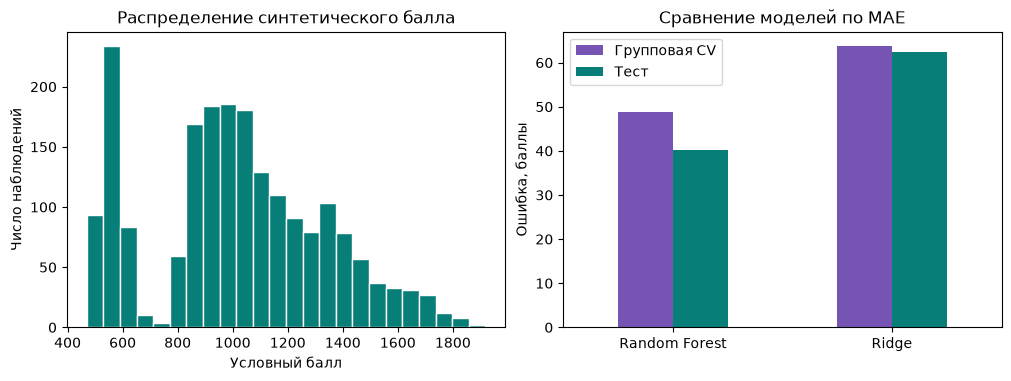

In [12]:
import matplotlib.pyplot as plt

names = {"ridge": "Ridge", "random_forest": "Random Forest"}
palette = {"ridge": "#7554b3", "random_forest": "#087e78"}
fig, axes = plt.subplots(1, 2, figsize=(10, 3.7), layout="constrained")
axes[0].hist(data[target], bins=24, color="#087e78", edgecolor="white")
axes[0].set(title="Распределение синтетического балла",
            xlabel="Условный балл", ylabel="Число наблюдений")

errors = comparison.set_index("model")[["cv_mae"]].join(results[["test_mae"]])
errors = errors.rename(index=names, columns={"cv_mae": "Групповая CV", "test_mae": "Тест"})
errors.plot.bar(ax=axes[1], rot=0, color=["#7554b3", "#087e78"])
axes[1].set(title="Сравнение моделей по MAE", xlabel="", ylabel="Ошибка, баллы")
plt.show()

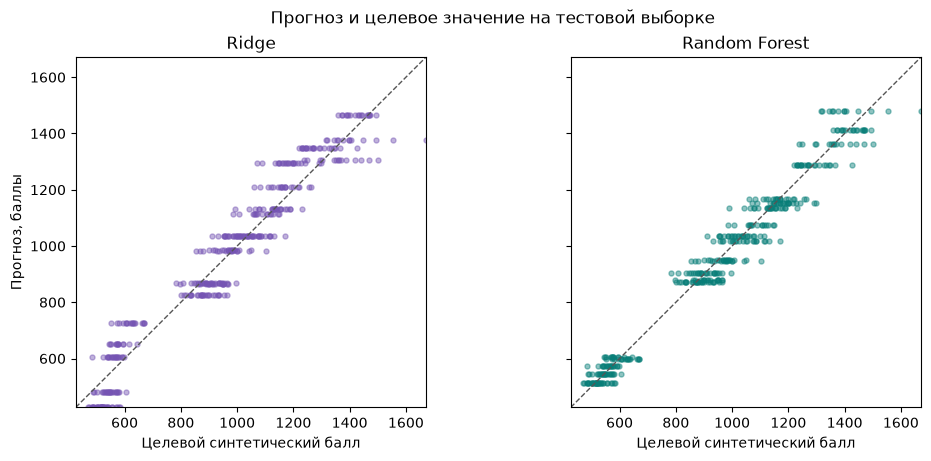

In [13]:
actual = test[target]
predicted = {name: model.predict(test[features]) for name, model in fitted.items()}
lower = min(actual.min(), *(values.min() for values in predicted.values()))
upper = max(actual.max(), *(values.max() for values in predicted.values()))

fig, axes = plt.subplots(1, 2, figsize=(10, 4.5), sharex=True, sharey=True,
                         layout="constrained")
for ax, (name, values) in zip(axes, predicted.items()):
    ax.scatter(actual, values, s=13, alpha=0.45, color=palette[name])
    ax.plot([lower, upper], [lower, upper], "--", color="#555555", linewidth=1)
    ax.set(xlim=(lower, upper), ylim=(lower, upper),
           title=names[name], xlabel="Целевой синтетический балл")
    ax.set_aspect("equal", adjustable="box")
axes[0].set_ylabel("Прогноз, баллы")
fig.suptitle("Прогноз и целевое значение на тестовой выборке")
plt.show()

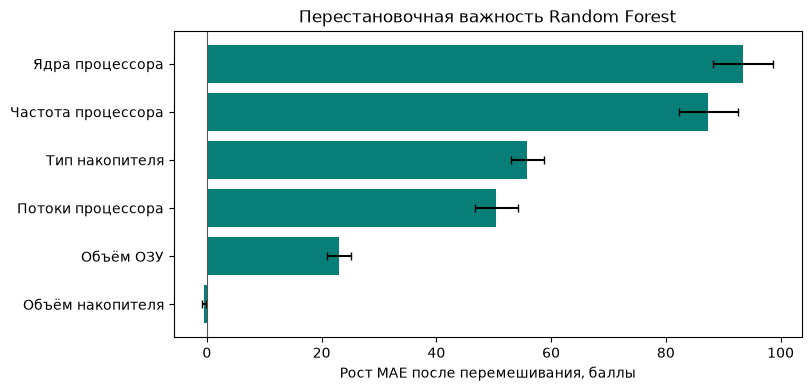

In [14]:
labels = {
    "cpu_cores": "Ядра процессора",
    "cpu_threads": "Потоки процессора",
    "cpu_frequency_ghz": "Частота процессора",
    "ram_gb": "Объём ОЗУ",
    "storage_gb": "Объём накопителя",
    "storage_type": "Тип накопителя",
}
importance = pd.read_csv(project_dir / "results/feature_importance.csv")
importance = importance.sort_values("mae_increase_mean")
fig, ax = plt.subplots(figsize=(8, 3.8), layout="constrained")
ax.barh(importance["feature"].map(labels), importance["mae_increase_mean"],
        xerr=importance["mae_increase_std"], color="#087e78", capsize=3)
ax.axvline(0, linewidth=0.8, color="#555555")
ax.set(title="Перестановочная важность Random Forest",
       xlabel="Рост MAE после перемешивания, баллы")
plt.show()

## Вывод

По групповой кросс-валидации выбрана Random Forest. На отложенных конфигурациях у неё также ниже MAE и RMSE и выше R². Повторы одной конфигурации не увеличивают число независимых конфигураций, поэтому при оценке важны 20 тестовых групп. Для выводов о реальных ноутбуках потребовались бы измерения производительности на реальных конфигурациях.

### Сверка с результатами проекта

В сохранённом запуске проекта CV MAE составила 48,8768 для Random Forest и 63,8219 для Ridge. На тесте для Random Forest получены MAE 40,1206, RMSE 52,6125 и R² 0,9671. В выводе этого ноутбука показан отдельный запуск со scikit-learn 1.8.0 и pandas 2.2.3. Версии отличаются от зафиксированных в requirements.txt (scikit-learn 1.9.1 и pandas 3.0.6), и численного совпадения для Random Forest нет. Для сверки в исходном окружении запустите все ячейки с ядром проекта. В обоих запусках по CV выбрана Random Forest.